# Paper: *An efficient stacking-based ensemble technique for early heart attack prediction* (Bhagat et al., 2025)

## Heart Attack Prediction: Reproduction and Leakage-Aware Improvement

**Part 1:** Reproduce the paper (6 classifiers + stacking)
**Part 2:** Identify and fix data leakage, then re-evaluate

 Load Dataset
Kaggle heart disease dataset. Expected: 1025 rows, 14 columns, no missing values (matches the paper).

In [14]:
import pandas as pd

df = pd.read_csv('heart.csv')  # adjust path if it's in a subfolder
print(df.shape)
print(df.head())
print(df['target'].value_counts())
print(df.isnull().sum())

(1025, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  
target
1    526
0    499
Name: count, dtype: int64
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


Duplicate Check
The paper does not mention duplicates. Checking how many unique patients there really are.

In [15]:
print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Unique rows:", df.drop_duplicates().shape[0])

Total rows: 1025
Duplicate rows: 723
Unique rows: 302


Train/Test Split 
The paper does not state its split ratio. 
**Assumption:** 80/20 stratified split, random_state=42.

In [16]:
from sklearn.model_selection import train_test_split

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(820, 13) (205, 13)
target
1    421
0    399
Name: count, dtype: int64
target
1    105
0    100
Name: count, dtype: int64


Train the Six Base Classifiers (Part 1)
Logistic Regression, Decision Tree, Random Forest, XGBoost, Naive Bayes, KNN.
StandardScaler is fit on training data only.

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42),
    'Naive Bayes': GaussianNB(),
    'KNN': KNeighborsClassifier()
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    print(f"{name} trained.")

Logistic Regression trained.
Decision Tree trained.
Random Forest trained.
XGBoost trained.
Naive Bayes trained.
KNN trained.


Metrics: Accuracy, Precision, Recall, F1, AUC.
Observation: Random Forest and XGBoost score exactly 1.0, which is a red flag for leakage.

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

results = []
for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

                 Model  Accuracy  Precision  Recall      F1     AUC
0  Logistic Regression    0.8098     0.7619  0.9143  0.8312  0.9298
1        Decision Tree    0.9854     1.0000  0.9714  0.9855  0.9857
2        Random Forest    1.0000     1.0000  1.0000  1.0000  1.0000
3              XGBoost    1.0000     1.0000  1.0000  1.0000  1.0000
4          Naive Bayes    0.8293     0.8070  0.8762  0.8402  0.9043
5                  KNN    0.8634     0.8738  0.8571  0.8654  0.9629


Stacking Ensemble (Part 1)

All six models as base learners, Logistic Regression as the meta-classifier, 5-fold internal CV.

Also scores 1.0, higher than the paper's 98.53%.

In [19]:
from sklearn.ensemble import StackingClassifier

base_estimators = [
    ('lr', LogisticRegression(max_iter=1000, random_state=42)),
    ('dt', DecisionTreeClassifier(random_state=42)),
    ('rf', RandomForestClassifier(random_state=42)),
    ('xgb', XGBClassifier(eval_metric='logloss', random_state=42)),
    ('nb', GaussianNB()),
    ('knn', KNeighborsClassifier())
]

stacking_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5
)

stacking_model.fit(X_train_scaled, y_train)
y_pred_stack = stacking_model.predict(X_test_scaled)
y_prob_stack = stacking_model.predict_proba(X_test_scaled)[:, 1]

stack_result = {
    'Model': 'Stacking Ensemble',
    'Accuracy': accuracy_score(y_test, y_pred_stack),
    'Precision': precision_score(y_test, y_pred_stack),
    'Recall': recall_score(y_test, y_pred_stack),
    'F1': f1_score(y_test, y_pred_stack),
    'AUC': roc_auc_score(y_test, y_prob_stack)
}
print(stack_result)

{'Model': 'Stacking Ensemble', 'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0, 'AUC': 1.0}


In [20]:
# Check overlap between train and test sets (ignoring index, using full row content)
train_full = X_train.copy()
train_full['target'] = y_train
test_full = X_test.copy()
test_full['target'] = y_test

train_rows = set(map(tuple, train_full.values))
test_rows = set(map(tuple, test_full.values))

overlap = train_rows.intersection(test_rows)
print("Number of identical rows in both train and test:", len(overlap))
print("Test set size:", len(test_full))
print("Percentage of test set that's leaked:", len(overlap)/len(test_full)*100, "%")

Number of identical rows in both train and test: 155
Test set size: 205
Percentage of test set that's leaked: 75.60975609756098 %


Proving the Leakage (Part 2 motivation)

Counting test rows that are identical to a training row.

 75.6% of the test set is leaked, so the models memorised rather than generalised.

Proposed Solution: Deduplicate, Then Split (Part 2)
1. Drop duplicates (1025 to 302 unique rows)
2. Same 80/20 stratified split
3. Verify zero leaked rows
4. Retrain all models with identical settings, so only the leakage changes

**Key finding:** every model drops, and stacking no longer beats the simpler models.

In [21]:
# Deduplicate
df_dedup = df.drop_duplicates().reset_index(drop=True)
print("Deduplicated shape:", df_dedup.shape)

X2 = df_dedup.drop('target', axis=1)
y2 = df_dedup['target']

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)

print("Train:", X2_train.shape, "Test:", X2_test.shape)

# Verify no leakage this time
train2_full = X2_train.copy(); train2_full['target'] = y2_train
test2_full = X2_test.copy(); test2_full['target'] = y2_test
overlap2 = set(map(tuple, train2_full.values)).intersection(set(map(tuple, test2_full.values)))
print("Leaked rows now:", len(overlap2))

# Scale
scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

# Train all 6 + stacking
models2 = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42),
    'Naive Bayes': GaussianNB(),
    'KNN': KNeighborsClassifier()
}

results2 = []
trained_models2 = {}
for name, model in models2.items():
    model.fit(X2_train_scaled, y2_train)
    trained_models2[name] = model
    y_pred = model.predict(X2_test_scaled)
    y_prob = model.predict_proba(X2_test_scaled)[:, 1]
    results2.append({
        'Model': name,
        'Accuracy': accuracy_score(y2_test, y_pred),
        'Precision': precision_score(y2_test, y_pred),
        'Recall': recall_score(y2_test, y_pred),
        'F1': f1_score(y2_test, y_pred),
        'AUC': roc_auc_score(y2_test, y_prob)
    })

base_estimators2 = [(n.lower().replace(' ', '_'), m) for n, m in models2.items()]
stacking2 = StackingClassifier(estimators=base_estimators2,
                                final_estimator=LogisticRegression(max_iter=1000, random_state=42),
                                cv=5)
stacking2.fit(X2_train_scaled, y2_train)
y_pred_s2 = stacking2.predict(X2_test_scaled)
y_prob_s2 = stacking2.predict_proba(X2_test_scaled)[:, 1]
results2.append({
    'Model': 'Stacking Ensemble',
    'Accuracy': accuracy_score(y2_test, y_pred_s2),
    'Precision': precision_score(y2_test, y_pred_s2),
    'Recall': recall_score(y2_test, y_pred_s2),
    'F1': f1_score(y2_test, y_pred_s2),
    'AUC': roc_auc_score(y2_test, y_prob_s2)
})

results2_df = pd.DataFrame(results2)
print(results2_df.round(4))

Deduplicated shape: (302, 14)
Train: (241, 13) Test: (61, 13)
Leaked rows now: 0
                 Model  Accuracy  Precision  Recall      F1     AUC
0  Logistic Regression    0.8033     0.8000  0.8485  0.8235  0.8712
1        Decision Tree    0.8033     0.8182  0.8182  0.8182  0.8019
2        Random Forest    0.7541     0.7647  0.7879  0.7761  0.8588
3              XGBoost    0.7213     0.7353  0.7576  0.7463  0.8323
4          Naive Bayes    0.7869     0.8333  0.7576  0.7937  0.8842
5                  KNN    0.7869     0.7778  0.8485  0.8116  0.8377
6    Stacking Ensemble    0.7541     0.7647  0.7879  0.7761  0.8680


Comparison Plots

Figure 1: accuracy on the leaky split vs. the clean split.

Figure 2: all five metrics on the clean split.

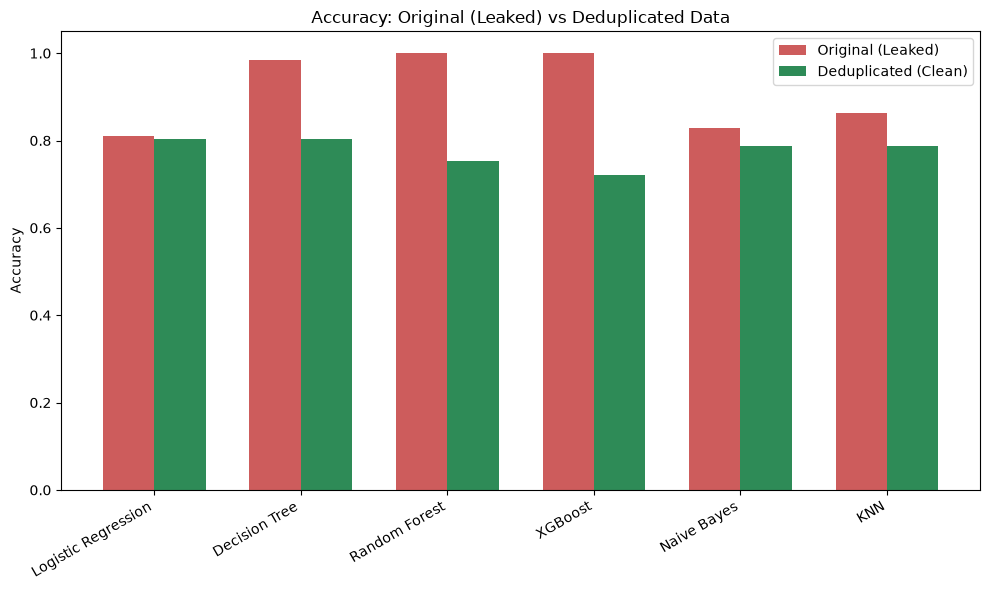

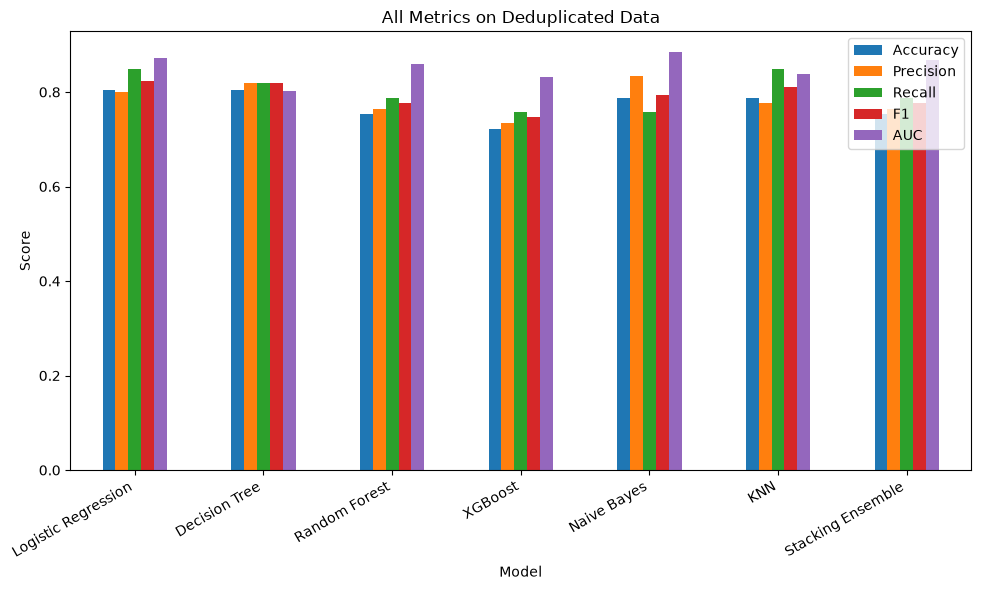

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Merge results1 (leaked) and results2 (clean) for comparison
results_df['Setting'] = 'Original (Leaked)'
results2_df['Setting'] = 'Deduplicated (Clean)'
combined = pd.concat([results_df, results2_df], ignore_index=True)

# Plot 1: Accuracy comparison bar chart
fig, ax = plt.subplots(figsize=(10, 6))
models_list = results_df['Model'].tolist()
x = np.arange(len(models_list))
width = 0.35

acc_leaked = results_df.set_index('Model')['Accuracy']
acc_clean = results2_df.set_index('Model')['Accuracy']

ax.bar(x - width/2, acc_leaked[models_list], width, label='Original (Leaked)', color='indianred')
ax.bar(x + width/2, acc_clean[models_list], width, label='Deduplicated (Clean)', color='seagreen')

ax.set_ylabel('Accuracy')
ax.set_title('Accuracy: Original (Leaked) vs Deduplicated Data')
ax.set_xticks(x)
ax.set_xticklabels(models_list, rotation=30, ha='right')
ax.legend()
plt.tight_layout()
plt.savefig('accuracy_comparison.png', dpi=150)
plt.show()

# Plot 2: All metrics for clean data only
fig, ax2 = plt.subplots(figsize=(10, 6))
results2_df.set_index('Model')[['Accuracy','Precision','Recall','F1','AUC']].plot(kind='bar', ax=ax2)
ax2.set_title('All Metrics on Deduplicated Data')
ax2.set_ylabel('Score')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('clean_metrics.png', dpi=150)
plt.show()